# Polymarket EDA

## Preamble

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

## Load data

In [10]:
# Open the database
con = sqlite3.connect("../polymarket-scraper/events.db")

In [11]:
# Read SQL db into DataFrame
df = pd.read_sql("SELECT * FROM events",con)

## Clean Data

In [12]:
print(df.columns)

Index(['id', 'ticker', 'slug', 'title', 'description', 'resolutionSource',
       'startDate', 'creationDate', 'endDate', 'image', 'icon', 'active',
       'closed', 'archived', 'new', 'featured', 'restricted', 'liquidity',
       'volume', 'openInterest', 'sortBy', 'category', 'published_at',
       'createdAt', 'updatedAt', 'competitive', 'volume24hr', 'volume1wk',
       'volume1mo', 'volume1yr', 'liquidityAmm', 'liquidityClob',
       'commentCount', 'markets', 'series', 'tags', 'cyom', 'closedTime',
       'showAllOutcomes', 'showMarketImages', 'enableNegRisk', 'seriesSlug',
       'negRiskAugmented', 'pendingDeployment', 'deploying',
       'requiresTranslation', 'eventMetadata', 'subcategory', 'updatedBy',
       'commentsEnabled', 'enableOrderBook', 'featuredImage', 'disqusThread',
       'automaticallyActive', 'negRisk', 'automaticallyResolved', 'createdBy',
       'negRiskMarketID', 'gmpChartMode', 'estimateValue', 'cumulativeMarkets',
       'startTime', 'eventDate', 'eventW

In [23]:
import sqlite3
import pandas as pd
import json
import ast

conn = sqlite3.connect('../polymarket-scraper/events.db')

# Pull the events table
events_df = pd.read_sql_query("SELECT id, title, markets FROM events LIMIT 20", conn)

for index, row in events_df.iterrows():
    print(f"Event: {row['title']}")
    
    # Parse the JSON string in the 'markets' column
    markets_data = json.loads(row['markets'])
    
    for market in markets_data:
        # The 'clobTokenIds' are typically stored as a stringified list in the JSON
        token_ids_str = market.get('clobTokenIds', '[]')
        
        # safely evaluate the string representation of the list into an actual Python list
        try:
            token_ids = ast.literal_eval(token_ids_str)
        except (ValueError, SyntaxError):
            token_ids = []
            
        print(f"  - Market: {market.get('question')}")
        print(f"  - 'Yes' Token: {token_ids[0] if len(token_ids) > 0 else 'N/A'}")
        print(f"  - 'No' Token: {token_ids[1] if len(token_ids) > 1 else 'N/A'}")

Event: NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?
  - Market: NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?
  - 'Yes' Token: 28182404005967940652495463228537840901055649726248190462854914416579180110833
  - 'No' Token: 47044845753450022047436429968808601130811164131571549682541703866165095016290
Event: NFL: Will the Falcons beat the Panthers by more than 3.5 points in their October 31st matchup?
  - Market: NFL: Will the Falcons beat the Panthers by more than 3.5 points in their October 31st matchup?
  - 'Yes' Token: 56511259653855886659936827966786013545784841144903847037967986812745595430432
  - 'No' Token: 14941478295244605382100055235924143559218628579320890713621951655794746924521
Event: (In-Game Trading) Will the 49ers beat the Packers by more than 3.5 points in their week three matchup?
  - Market: (In-Game Trading) Will the 49ers beat the Packers by more than 3.5 points in the

0           https://www.nba.com/games
1         https://www.nfl.com/scores/
2         https://www.nfl.com/scores/
3             https://norwaychess.no/
4                http://nba.com/games
                     ...             
386248                               
386249                               
386250                               
386251                               
386252                               
Name: resolutionSource, Length: 386253, dtype: str

closed
True     375653
False     10600
Name: count, dtype: Int64

In [15]:
# Set the correct type for boolean columns
boolean_columns = (
    "active",
    "closed",
    "archived",
    "new",
    "featured",
    "restricted",
    "commentsEnabled",
    "enableOrderBook",
    "negRisk",
    "cyom",
    "showAllOutcomes",
    "showMarketImages",
    "automaticallyResolved",
    "enableNegRisk",
    "automaticallyActive",
    "live",
    "ended",
    "estimateValue",
    "cantEstimate",
    "pendingDeployment",
    "deploying"
)

df[[*boolean_columns]] = df[[*boolean_columns]].astype('boolean')

In [16]:
# Parse the string JSON values
object_columns = (
    "markets",
    "tags",
    "eventCreators",
)

In [17]:
def parse_json(json_str : str) : 
    return json.loads(json_str) if isinstance(json_str,str) else np.nan
    
df[[*object_columns]] = df[[*object_columns]].map(parse_json)

In [18]:
df[[*object_columns]]

,markets,tags,eventCreators
0,"[{'id': '239826', 'question': 'NBA: Will the M...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
1,"[{'id': '239167', 'question': 'NFL: Will the F...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
2,"[{'id': '238885', 'question': '(In-Game Tradin...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
3,"[{'id': '245948', 'question': '2022 Norway Che...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
4,"[{'id': '239496', 'question': 'NBA: Will the H...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
...,...,...,...
386248,"[{'id': '255435', 'question': 'Trump $83.3m ve...","[{'id': '164', 'label': 'law', 'slug': 'law', ...",NaN
386249,"[{'id': '255440', 'question': 'Boeing whistleb...","[{'id': '846', 'label': 'Boeing', 'slug': 'boe...",NaN
386250,"[{'id': '255443', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
386251,"[{'id': '255447', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN


In [19]:
print(df.iloc[0]['markets'])

[{'id': '239826', 'question': 'NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?', 'conditionId': '0x064d33e3f5703792aafa92bfb0ee10e08f461b1b34c02c1f02671892ede1609a', 'slug': 'nba-will-the-mavericks-beat-the-grizzlies-by-more-than-5pt5-points-in-their-december-4-matchup', 'resolutionSource': 'https://www.nba.com/games', 'endDate': '2021-12-04T00:00:00Z', 'category': 'Sports', 'liquidity': '50.000009', 'startDate': '2021-12-04T19:35:03.796Z', 'fee': '20000000000000000', 'image': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png', 'icon': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png', 'description': 'In the upcoming NBA game, scheduled for December 4:\n\nIf the Dall

## Preliminary Analysis

### General statistics for interesting numerical columns

In [20]:
interesting_columns = (
    "liquidity",
    "volume",
    "openInterest",
    "volume24hr",
    "volume1wk",
    "volume1mo",
    "volume1yr",
    "commentCount",
)

### Addressing Hypothesis: Are a majority of high-volume markets related to Sports?
To answer this, let's look at the distribution of trading volume across the top categories.

/tmp/ipykernel_4009321/476895858.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')


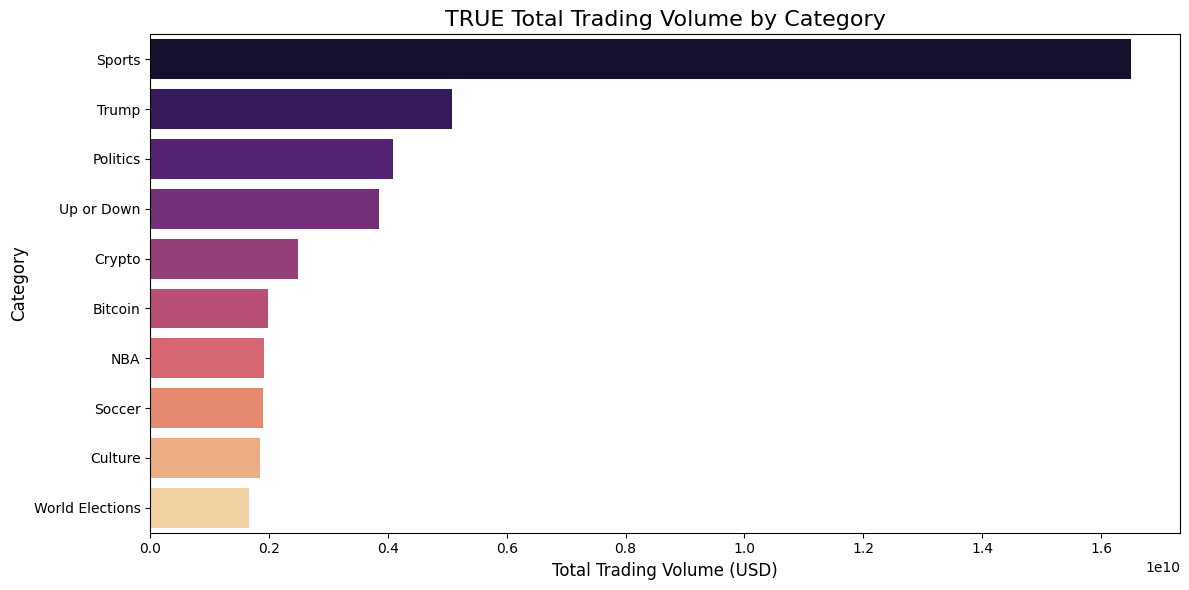

Top 10 True Categories by % of Total Volume:
primary_category
Sports             24.39%
Trump               7.52%
Politics            6.03%
Up or Down          5.70%
Crypto              3.68%
Bitcoin             2.93%
NBA                 2.84%
Soccer              2.80%
Culture             2.74%
World Elections     2.46%
Name: volume, dtype: str


In [21]:
# extraction of the 'Primary Category' from the tags list
def extract_primary_category(row):
    # If the standard category exists, use it
    if pd.notna(row['category']) and row['category'] != '':
        return row['category']
    
    # Otherwise, parse the tags column if it's a valid list of dictionaries
    if isinstance(row['tags'], list) and len(row['tags']) > 0:
        # We can extract the label from the first tag 
        # (usually the broadest/most representative tag)
        return row['tags'][0].get('label', 'Unknown')
        
    return 'Unknown'

# Apply our custom extractor
df['primary_category'] = df.apply(extract_primary_category, axis=1)

# Now, recalculate the volume with our newly populated categories!
total_volume = df['volume'].sum()
true_category_volume = df.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(10)

# Plotting the adjusted data
plt.figure(figsize=(12, 6))
sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')
plt.title('TRUE Total Trading Volume by Category', fontsize=16)
plt.xlabel('Total Trading Volume (USD)', fontsize=12)
plt.ylabel('Category', fontsize=12)
# formatter = ticker.FuncFormatter(lambda x, pos: f'${x*1e-9:,.1f}B') # Format to Billions now!
# plt.gca().xaxis.set_major_formatter(formatter)
plt.tight_layout()
plt.show()

# Print the real percentages
print("Top 10 True Categories by % of Total Volume:")
print((true_category_volume / total_volume * 100).apply(lambda x: f"{x:.2f}%"))

In [22]:
# Check the date intervals for the events data
date_columns = ['startDate', 'endDate', 'createdAt']

# Convert to datetime to easily find min and max limits
for col in date_columns:
    if col in df.columns:
        # Convert to datetime, coercing errors to NaT
        df[col] = pd.to_datetime(df[col], errors='coerce')

print("=== Data Date Intervals ===")
if 'createdAt' in df.columns:
    print(f"Earliest Event Created: {df['createdAt'].min()}")
    print(f"Latest Event Created:   {df['createdAt'].max()}")
    print("-" * 25)

if 'startDate' in df.columns:
    print(f"Earliest Start Date:    {df['startDate'].min()}")
    print(f"Latest Start Date:      {df['startDate'].max()}")
    print("-" * 25)

if 'endDate' in df.columns:
    print(f"Earliest End Date:      {df['endDate'].min()}")
    print(f"Latest End Date:        {df['endDate'].max()}")


=== Data Date Intervals ===
Earliest Event Created: 2022-07-27 14:40:02.074000+00:00
Latest Event Created:   2026-04-19 21:17:00.973232+00:00
-------------------------
Earliest Start Date:    2020-10-02 00:00:00+00:00
Latest Start Date:      2026-04-17 22:00:26+00:00
-------------------------
Earliest End Date:      0024-01-15 00:00:00+00:00
Latest End Date:        2029-01-20 00:00:00+00:00


In [58]:
import json

print("=== Closed Markets by Volume ===")

closed_markets = []

for markets_str in df['markets'].dropna():
    try:
        # Depending on how the db was read, `markets_str` might already be a list or a string
        if isinstance(markets_str, str):
            markets_list = json.loads(markets_str)
        else:
            markets_list = markets_str
            
        for m in markets_list:
            is_closed = m.get('closed', False)
            if is_closed:
                volume = float(m.get('volumeNum', 0) or 0)
                clob_token_ids_str = m.get('clobTokenIds', '[]')
                outcomes = m.get('outcomes', [])
                market_name = m.get('question', m.get('slug', 'Unknown Name')) 
                
                closed_markets.append({
                    'clob_token_ids': clob_token_ids_str,
                    'outcomes': outcomes,
                    'name': market_name,
                    'volume': volume
                })
    except Exception as e:
        # print(f"Error parsing market: {e}")
        continue

# Sort by highest volume descending
closed_markets.sort(key=lambda x: x['volume'], reverse=True)

# Print top 20
for i, market in enumerate(closed_markets[:100], 1):
    print(f"{i}. Vol: ${market['volume']:,.2f} | Name: {market['name']}")
    print(f"   ClobTokenIds: {market['clob_token_ids']}\n   Outcomes: {market['outcomes']}")

=== Closed Markets by Volume ===
1. Vol: $1,531,479,284.50 | Name: Will Donald Trump win the 2024 US Presidential Election?
   ClobTokenIds: ["21742633143463906290569050155826241533067272736897614950488156847949938836455", "48331043336612883890938759509493159234755048973500640148014422747788308965732"]
   Outcomes: ["Yes", "No"]
2. Vol: $1,037,039,118.19 | Name: Will Kamala Harris win the 2024 US Presidential Election?
   ClobTokenIds: ["69236923620077691027083946871148646972011131466059644796654161903044970987404", "87584955359245246404952128082451897287778571240979823316620093987046202296181"]
   Outcomes: ["Yes", "No"]
3. Vol: $400,409,526.89 | Name: Will Donald Trump be inaugurated?
   ClobTokenIds: ["45714870634090908403813747458214625542376052548606303175331201110938821302832", "81903344213938200361285862519406650037576398044514748634670292917494365866240"]
   Outcomes: ["Yes", "No"]
4. Vol: $378,011,506.51 | Name: Will the Sacramento Kings win the 2025 NBA Finals?
   ClobTokenId

In [63]:
import sys
import json
import ast
import pandas as pd
import sqlite3

# Add scraper directory to path so we can import from fetch_markets.py
sys.path.append("../polymarket-scraper")
from fetch_markets import get_prices_history
from requests_ratelimiter import LimiterSession

def fetch_top_events_history(markets_list, limit=100):
    session = LimiterSession(per_second=5)
    con_out = sqlite3.connect("../polymarket-scraper/price_history.db")
    
    skipped_count = 0
    valid_records = []
    
    print(f"Fetching data for top {limit} markets...\n")
    
    for idx, market in enumerate(markets_list[:limit]):
        event_name = market['name']
        
        try:
            # Parse the stringified clob token IDs list
            tokens_str = market['clob_token_ids']
            if isinstance(tokens_str, str):
                try:
                    tokens = json.loads(tokens_str)
                except:
                    tokens = ast.literal_eval(tokens_str)
            else:
                tokens = tokens_str
        except Exception:
            tokens = []
            
        outcomes = market.get('outcomes', [])
        
        if not tokens or len(tokens) == 0:
            skipped_count += 1
            continue
            
        skip_event = False
        event_data = []
        
        # Iterating through the tokens (these represent 'Yes', 'No', etc. based on index)
        for i, token_id in enumerate(tokens):
            # Try to grab the exact outcome string (e.g., 'Yes'), fallback to 'Outcome_i'
            outcome_label = outcomes[i] if i < len(outcomes) else f"Outcome_{i}"
            
            try:
                resp = get_prices_history(session, {"market": token_id, "interval": "max"})
                if resp.status_code == 200:
                    history = resp.json().get("history", [])
                    
                    if not history or len(history) == 0:
                        skip_event = True
                        break
                        
                    # Fetch all price values for this outcome
                    prices = [d['p'] for d in history]
                    
                    # If min and max price of an outcome is the same, skip the entire event
                    if min(prices) == max(prices):
                        skip_event = True
                        break
                        
                    # Tag all records with metadata
                    for rec in history:
                        rec['market_id'] = token_id
                        rec['event_name'] = event_name
                        rec['outcome'] = outcome_label
                        
                    event_data.extend(history)
                else:
                    skip_event = True
                    break
            except Exception as e:
                skip_event = True
                break
                
        # Only process if both 'Yes' and 'No' endpoints were successful and met requirements
        if skip_event or not event_data:
            print(f"[{idx+1}/{limit}] SKIPPED: {event_name}")
            skipped_count += 1
        else:
            # Event passed! All outcomes gathered properly
            print(f"[{idx+1}/{limit}] SUCCESS - Fetched {len(event_data)} historical points for: {event_name}")
            valid_records.extend(event_data)
            
    # Save the successful extractions to the DB
    if valid_records:
        df_final = pd.DataFrame(valid_records)
        df_final.to_sql("price_history_top100", con_out, if_exists="replace", index=False)
        print(f"\n-> Extracted mapping saved to new table 'price_history_top100'")
        print(f"-> Total records written: {len(df_final)}")
    else:
        print("\nNo valid records could be processed and saved.")
        
    print(f"-> Total events skipped: {skipped_count}")
    con_out.close()

# Trigger function with our pre-compiled 'closed_markets' list
fetch_top_events_history(closed_markets, limit=1000)

Fetching data for top 1000 markets...

[1/1000] SKIPPED: Will Donald Trump win the 2024 US Presidential Election?
[2/1000] SKIPPED: Will Kamala Harris win the 2024 US Presidential Election?
[3/1000] SKIPPED: Will Donald Trump be inaugurated?
[4/1000] SKIPPED: Will the Sacramento Kings win the 2025 NBA Finals?
[5/1000] SKIPPED: Will Nicolae Ciucă win the 2024 Romanian Presidential election?
[6/1000] SUCCESS - Fetched 4315 historical points for: US forces enter Iran by April 30?
[7/1000] SKIPPED: Will Zelenskyy wear a suit before July?
[8/1000] SKIPPED: Will any other Republican Politician win the 2024 US Presidential Election?
[9/1000] SKIPPED: Fed decreases interest rates by 50+ bps after January 2026 meeting?
[10/1000] SKIPPED: Fed increases interest rates by 25+ bps after January 2026 meeting?
[11/1000] SUCCESS - Fetched 3971 historical points for: US x Iran ceasefire by April 7?
[12/1000] SKIPPED: Will the Fed increase interest rates by 25+ bps after the March 2026 meeting?
[13/1000

### Read price_history.db data

Total records: 3971
Date Range: 2026-03-24 18:10:24 to 2026-04-11 00:20:53



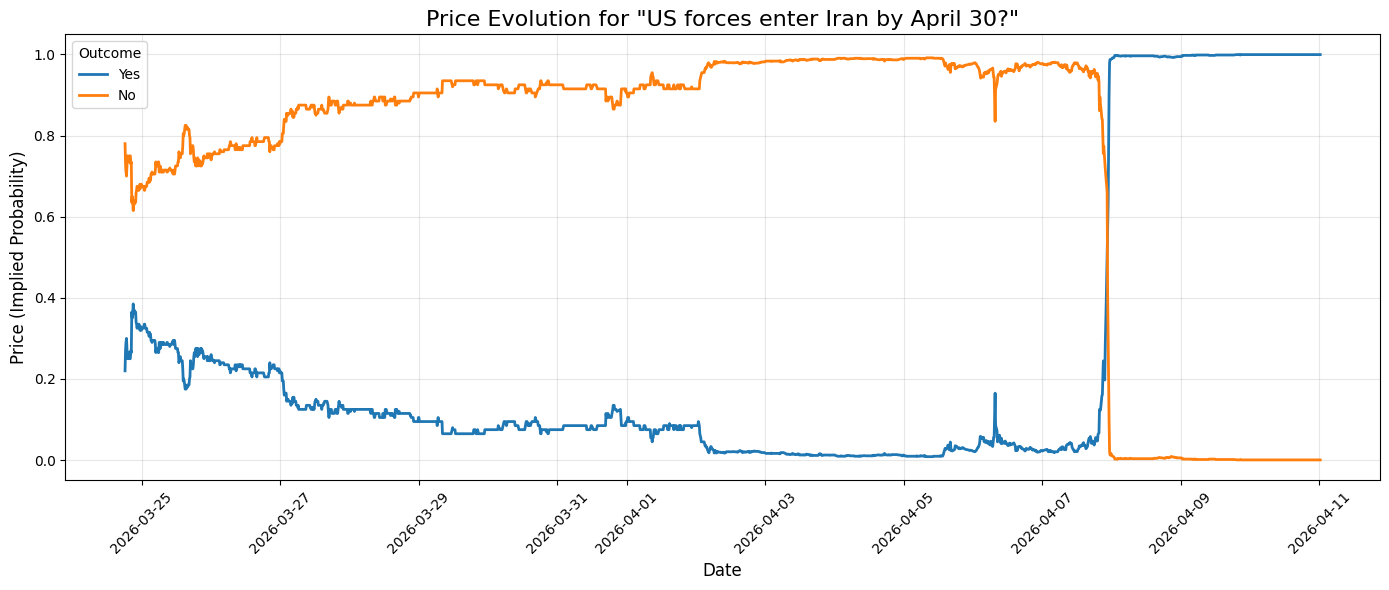

,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
No,1926.0,0.762882,0.329635,0.0005,0.765,0.905,0.9675,0.9915
Yes,2045.0,0.237108,0.331230,0.0085,0.035,0.095,0.2350,0.9995


In [60]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the price history database
con_ph = sqlite3.connect("../polymarket-scraper/price_history.db")
df_ph = pd.read_sql("SELECT * FROM price_history", con_ph)

# Convert the UNIX timestamp 't' to a readable datetime
df_ph['datetime'] = pd.to_datetime(df_ph['t'], unit='s')

# Map the market_id to 'Yes' and 'No' outcomes for Oprah Winfrey 2028
outcome_map = {
    "82855088893985825781350466813737280564000275725006328179621744619327480699369": "Yes",
    "55194745453074297560900438908357749978780021444937743754846798173575377021411": "No"
}
df_ph['outcome'] = df_ph['market_id'].map(outcome_map).fillna(df_ph['market_id'])

print(f"Total records: {len(df_ph)}")
print(f"Date Range: {df_ph['datetime'].min()} to {df_ph['datetime'].max()}\n")

# Plot the price evolution for both market tokens
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_ph, x='datetime', y='p', hue='outcome', linewidth=2)
plt.title('Price Evolution for "US forces enter Iran by April 30?"', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (Implied Probability)', fontsize=12)
plt.legend(title='Outcome')
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display summary statistics
display(df_ph.groupby('outcome')['p'].describe())

In [61]:
df_ph['datetime']

0      2026-03-24 18:10:24
1      2026-03-24 18:20:26
2      2026-03-24 18:30:26
3      2026-03-24 18:40:27
4      2026-03-24 18:50:28
               ...        
3966   2026-04-10 23:30:23
3967   2026-04-10 23:40:24
3968   2026-04-10 23:50:58
3969   2026-04-11 00:10:54
3970   2026-04-11 00:20:53
Name: datetime, Length: 3971, dtype: datetime64[s]

In [64]:
import sqlite3
import pandas as pd

# Connect to the price history database
con_ph_top = sqlite3.connect("../polymarket-scraper/price_history.db")

try:
    # Query distinct event names from the newly created table
    query = "SELECT DISTINCT event_name FROM price_history_top100"
    df_events = pd.read_sql(query, con_ph_top)
    
    print(f"Total unique events to categorize: {len(df_events)}\n")
    print("=== Event Names ===")
    for idx, event_name in enumerate(df_events['event_name'].tolist(), 1):
        print(f"{idx}. {event_name}")
except Exception as e:
    print(f"Error reading from database: {e}")
finally:
    con_ph_top.close()


Total unique events to categorize: 70

=== Event Names ===
1. US forces enter Iran by April 30?
2. US x Iran ceasefire by April 7?
3. Netanyahu out by March 31?
4. Will Chelsea win the 2025–26 English Premier League?
5. US forces enter Iran by March 31?
6. Will the Iranian regime fall by March 31?
7. US x Iran ceasefire by March 31?
8. Will the Charlotte Hornets win the 2026 NBA Finals?
9. Will Atletico Madrid win the 2025–26 La Liga?
10. Military action against Iran ends by April 17, 2026?
11. Will the Chicago Bulls win the 2026 NBA Finals?
12. US x Iran ceasefire by April 15?
13. Will Bitcoin reach $150,000 in March?
14. US forces enter Iran by December 31?
15. US x Iran ceasefire by April 30?
16. Will Crude Oil (CL) hit (HIGH) $100 by end of March?
17. Will Movement for a Better Hungary (Jobbik) win the most seats in the next Hungarian parliamentary election?
18. Will Phạm Minh Chính be the next President of Vietnam?
19. Will the Golden State Warriors win the 2026 NBA Finals?
20. Wi

In [68]:
import sqlite3
import pandas as pd

# Connect to the price history database
con_ph_cats = sqlite3.connect("../polymarket-scraper/price_history.db")

try:
    # Read the manually labeled categories
    df_categories = pd.read_sql("SELECT * FROM event_categories", con_ph_cats)
    
    # Read the actual price history data
    df_prices = pd.read_sql("SELECT * FROM price_history_top100", con_ph_cats)
    
    # Merge them together on the event_name
    df_merged = df_prices.merge(df_categories, on='event_name', how='left')
    
    print(f"Total labeled events: {len(df_categories)}")
    print(f"Total price history records: {len(df_merged)}")
    
    # Display the merged dataframe containing prices, timestamps, and your custom categories!
    display(df_merged)
    
    # Optionally, look at the distribution of the labels
    if not df_categories.empty:
        print("\n=== Category Distribution ===")
        display(df_categories['category'].value_counts().to_frame())
except Exception as e:
    print(f"Error reading from database: {e}")
    print("Ensure you have run the 'label_events.py' script and labeled at least one event!")
finally:
    con_ph_cats.close()

Total labeled events: 70
Total price history records: 232253


,t,p,market_id,event_name,outcome,category
0,1774114257,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
1,1774114846,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
2,1774115445,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
3,1774116052,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
4,1774116639,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,[,Politics
...,...,...,...,...,...,...
232248,1775352645,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232249,1775353240,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232250,1775353839,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports
232251,1775355041,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,"""",Sports



=== Category Distribution ===


,count
category,
Sports,33
Politics,26
Finance,6
Crypto,5


In [71]:
# Fix outcome parsing artifacts
df_merged['outcome'] = df_merged['outcome'].replace({'"': 'Yes', '[': 'No'})

# Sort the values chronologically first so the arrays are in order of time
df_sorted = df_merged.sort_values(by=['event_name', 'outcome', 't'])

# Group by the event properties to aggregate timestamps and prices into lists
df_grouped = df_sorted.groupby(['event_name', 'category', 'outcome']).agg({
    't': list,
    'p': list
}).reset_index()

# Rename columns to match your exact requested format
df_grouped = df_grouped.rename(columns={
    'event_name': 'Event_name',
    't': 'timestamp',
    'p': 'price'
})

print(f"Total grouped records (Event + Outcome): {len(df_grouped)}")

# Display the grouped dataframe
display(df_grouped)

Total grouped records (Event + Outcome): 140


,Event_name,category,outcome,timestamp,price
0,Arizona Wildcats vs. Michigan Wolverines,Sports,No,"[1774819854, 1774820447, 1774821043, 177482224...","[0.515, 0.5, 0.575, 0.575, 0.565, 0.485, 0.485..."
1,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,"[1774820452, 1774821048, 1774822252, 177482285...","[0.5, 0.425, 0.425, 0.435, 0.515, 0.515, 0.515..."
2,Connecticut Huskies vs. Michigan Wolverines,Sports,No,"[1775362240, 1775362842, 1775363445, 177536404...","[0.27, 0.275, 0.275, 0.265, 0.265, 0.265, 0.26..."
3,Connecticut Huskies vs. Michigan Wolverines,Sports,Yes,"[1775362246, 1775362848, 1775363459, 177536405...","[0.73, 0.725, 0.725, 0.735, 0.735, 0.735, 0.73..."
4,Hawks vs. Knicks,Sports,No,"[1776089440, 1776090053, 1776090649, 177609124...","[0.33, 0.33, 0.405, 0.425, 0.41, 0.365, 0.365,..."
...,...,...,...,...,...
135,Will the Iranian regime fall by March 31?,Politics,Yes,"[1774114248, 1774114841, 1774115441, 177411604...","[0.9865, 0.9855, 0.9855, 0.9875, 0.9875, 0.987..."
136,Will the Los Angeles Clippers win the 2026 NBA...,Sports,No,"[1774114244, 1774114837, 1774115438, 177411603...","[0.0195, 0.0195, 0.0195, 0.0195, 0.0195, 0.019..."
137,Will the Los Angeles Clippers win the 2026 NBA...,Sports,Yes,"[1774114238, 1774114829, 1774115434, 177411602...","[0.9805, 0.9805, 0.9805, 0.9805, 0.9805, 0.980..."
138,Will the Miami Heat win the 2026 NBA Finals?,Sports,No,"[1774114248, 1774114841, 1774115441, 177411604...","[0.0115, 0.0115, 0.0115, 0.0115, 0.0115, 0.011..."


In [103]:
df_merged.to_csv("merged_price_history_data_forecasting_model.csv", index=False)
df_grouped.to_csv("grouped_price_history_data_forecasting_model.csv", index=False)

In [77]:
df_merged_yes = df_merged[df_merged['outcome'] == 'Yes']

df_merged_yes

,t,p,market_id,event_name,outcome,category
2212,1774114258,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2213,1774114847,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2214,1774115445,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2215,1774116053,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2216,1774116639,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
...,...,...,...,...,...,...
232248,1775352645,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232249,1775353240,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232250,1775353839,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232251,1775355041,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports


### Checking intervals 

This is expected to be 10ish minutes

In [78]:
import numpy as np

# Calculate the time interval (difference between consecutive timestamps) for each array
def get_avg_interval(timestamps):
    if len(timestamps) > 1:
        # Calculate differences between consecutive items
        diffs = np.diff(timestamps)
        # Return the median difference in minutes
        return np.median(diffs) / 60 
    return None

df_grouped['median_interval_minutes'] = df_grouped['timestamp'].apply(get_avg_interval)

print("=== Median Time Interval (in minutes) per Event ===")
display(df_grouped[['Event_name', 'outcome', 'median_interval_minutes']].head(10))

# Overall average across all events
overall_median = df_grouped['median_interval_minutes'].median()
print(f"\nOverall median interval across all markets: {overall_median:.2f} minutes")

=== Median Time Interval (in minutes) per Event ===


,Event_name,outcome,median_interval_minutes
0,Arizona Wildcats vs. Michigan Wolverines,No,10.033333
1,Arizona Wildcats vs. Michigan Wolverines,Yes,10.066667
2,Connecticut Huskies vs. Michigan Wolverines,No,10.016667
3,Connecticut Huskies vs. Michigan Wolverines,Yes,10.800000
4,Hawks vs. Knicks,No,10.033333
5,Hawks vs. Knicks,Yes,10.066667
6,Heat vs. Hornets,No,10.016667
7,Heat vs. Hornets,Yes,10.716667
8,Hornets vs. Magic,No,10.016667
9,Hornets vs. Magic,Yes,10.066667



Overall median interval across all markets: 10.00 minutes


In [83]:
# Create a copy of the un-grouped merged data using df_merged_yes
df_resample = df_merged_yes.copy()

# Ensure datetime is set and set it as the index for resampling
df_resample['datetime'] = pd.to_datetime(df_resample['t'], unit='s')
df_resample.set_index('datetime', inplace=True)

# Group by our keys and resample to 30-minute intervals, taking the mean of the prices
df_30m = df_resample.groupby(['event_name', 'category', 'outcome']).resample('30min')['p'].mean().reset_index()

# Drop intervals that had no data (NaNs)
df_30m = df_30m.dropna(subset=['p'])

# Convert datetime back to Unix timestamps for consistency
# Using a map to safely process the datetime to a unix seconds timestamp
df_30m['t'] = df_30m['datetime'].apply(lambda x: int(x.timestamp()))


df_30m = df_30m.rename(columns={
    'event_name': 'Event_name',
    't': 'timestamp',
    'p': 'price'
})

# # Re-group the 30-minute data back into arrays (lists)
# df_grouped_30m = df_30m.sort_values(by=['event_name', 'outcome', 't']).groupby(
#     ['event_name', 'category', 'outcome']
# ).agg({
#     't': list,
#     'p': list
# }).reset_index()

# # Rename columns to match the requested format
# df_grouped_30m = df_grouped_30m.rename(columns={
#     'event_name': 'Event_name',
#     't': 'timestamp',
#     'p': 'price'
# })

print(f"Total records after 30-minute resampling: {len(df_30m)}")
display(df_30m.head(10))

Total records after 30-minute resampling: 42971


,Event_name,category,outcome,datetime,price,timestamp
0,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 21:30:00,0.4625,1774819800
1,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:00:00,0.4300,1774821600
2,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:30:00,0.5150,1774823400
3,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:00:00,0.5150,1774825200
4,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:30:00,0.5625,1774827000
5,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:00:00,0.5150,1774828800
6,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:30:00,0.5150,1774830600
7,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:00:00,0.5150,1774832400
8,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:30:00,0.5150,1774834200
9,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 02:00:00,0.5150,1774836000


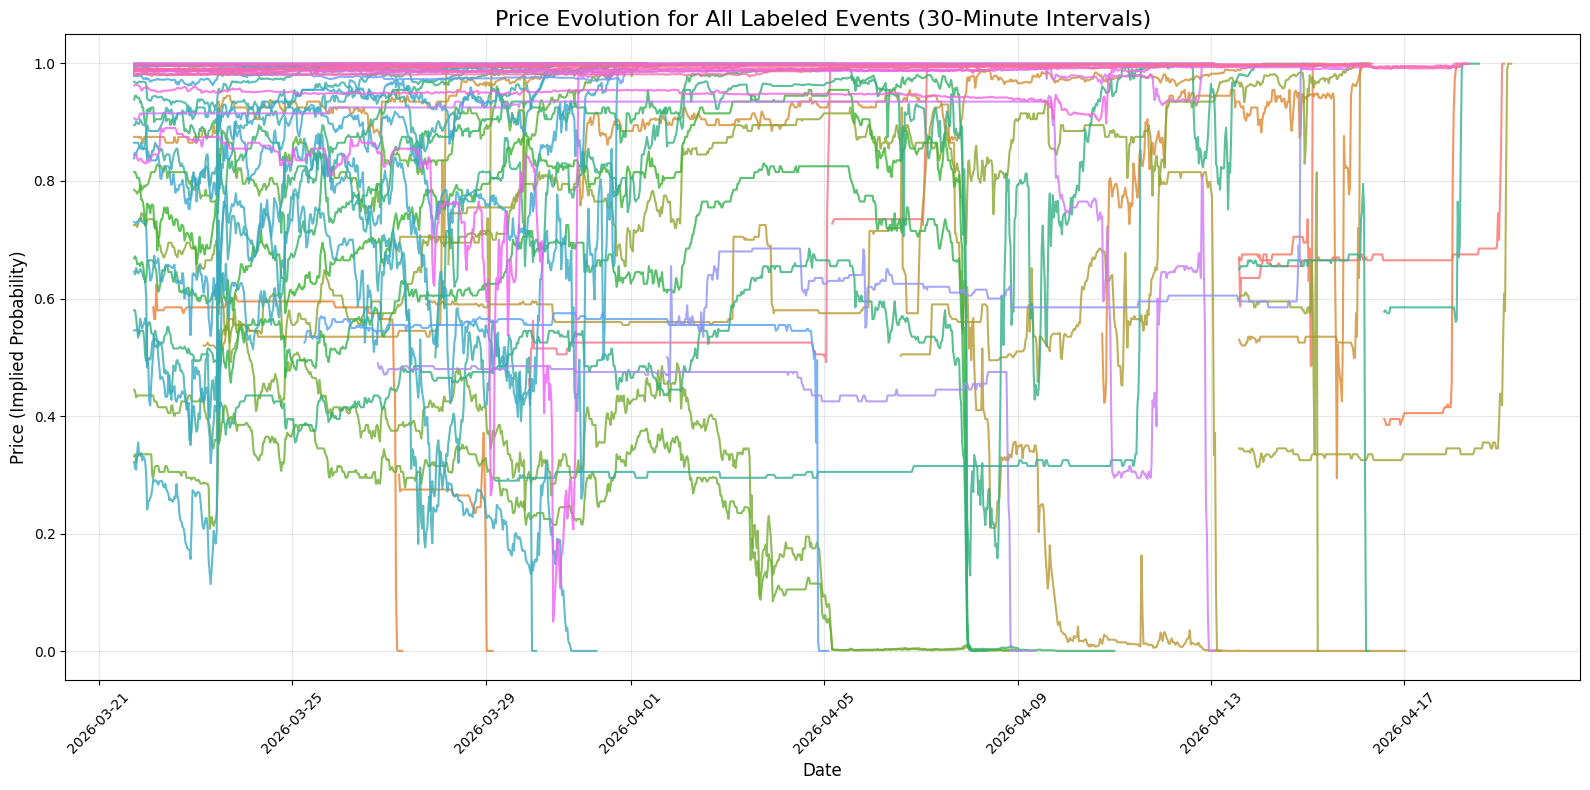

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

# Plot each event's price over time
sns.lineplot(data=df_30m, x='datetime', y='price', hue='Event_name', alpha=0.8, linewidth=1.5)

plt.title('Price Evolution for All Labeled Events (30-Minute Intervals)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (Implied Probability)', fontsize=12)

# # Place the legend outside the plot area to avoid cluttering if there are many events
# if df_30m['Event_name'].nunique() > 10:
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', title='Event Name')
# else:
#     plt.legend(title='Event Name')

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 55.1 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.2/300.2 MB 48.0 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Creating 8 lag features (4 hours total)...
Training shapes: X=(33928, 14), y=(33928,)
Testing shapes: X=(8483, 14), y=(8483,)
Training XGBoost Regressor...

--- Model Evaluation ---
RMSE: 0.0010
MAE:  0.0003

--- Top 10 Feature Importances ---


,Feature,Importance
4,price_lag_1,0.985764
6,price_lag_3,0.002849
8,price_lag_5,0.001819
3,category_Sports,0.001621
7,price_lag_4,0.001427
9,price_lag_6,0.001386
12,rolling_mean_4h,0.001310
5,price_lag_2,0.001091
10,price_lag_7,0.000837
11,price_lag_8,0.000670


/tmp/ipykernel_4009321/3156486442.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')


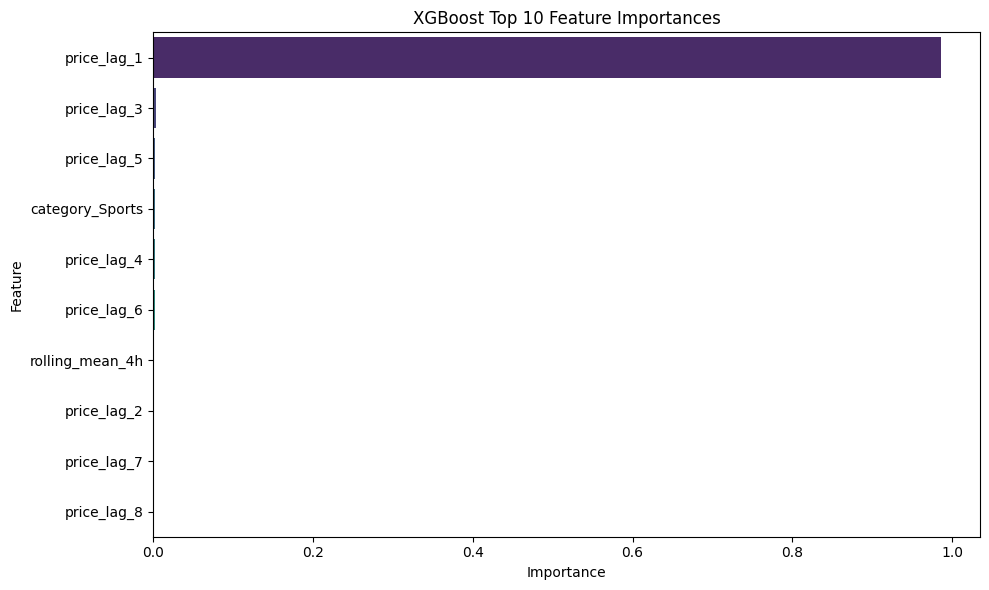

In [88]:
!pip install xgboost scikit-learn

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Prepare copy of data and sort chronologically per event
df_ml = df_30m.copy()
df_ml = df_ml.sort_values(by=['Event_name', 'datetime'])

# 2. Encode the category column using One-Hot Encoding
df_ml = pd.get_dummies(df_ml, columns=['category'], drop_first=False)

# 3. Create 4-hour sliding window features 
# Since data is in 30-min intervals, 4 hours = 8 intervals
window_size = 8

print(f"Creating {window_size} lag features (4 hours total)...")
for i in range(1, window_size + 1):
    df_ml[f'price_lag_{i}'] = df_ml.groupby('Event_name')['price'].shift(i)

# Add rolling window statistics (mean and std) over the preceding 4 hours
df_ml['rolling_mean_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).mean()
)
df_ml['rolling_std_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).std()
)

# Drop rows with NaN values resulting from the shift (the first 4 hours of each event)
df_ml = df_ml.dropna().reset_index(drop=True)

# 4. Separate Features (X) and Target (y)
# Target is the current price. We predict it using the 4 hours of past prices.
exclude_cols = ['Event_name', 'outcome', 'timestamp', 'datetime', 't', 'price']
feature_cols = [c for c in df_ml.columns if c not in exclude_cols]

X = df_ml[feature_cols]
y = df_ml['price']

# 5. Temporal Train/Test Split (80/20)
# We avoid random shuffling to prevent data leakage from the future into the past
split_idx = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Testing shapes: X={X_test.shape}, y={y_test.shape}")

# 6. Train XGBoost Regressor
# Values are bounded 0-1, so we could use a logistic objective or clip predictions
model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective='reg:squarederror'
)

print("Training XGBoost Regressor...")
model.fit(X_train, y_train)

# 7. Evaluate Model
preds = model.predict(X_test)
preds = np.clip(preds, 0, 1)  # Ensure probabilities stay between 0 and 1

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)

print("\n--- Model Evaluation ---")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

# 8. Feature Importances
importance = pd.DataFrame({
    'Feature': feature_cols, 
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 10 Feature Importances ---")
display(importance.head(10))

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Top 10 Feature Importances")
plt.tight_layout()
plt.show()


Top 1 Event (Highest Variance): Will Xander Schauffele win the 2026 Masters tournament?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0367
MAE (Mean Absolute Error):      0.0322
Directional Accuracy:           50.0%



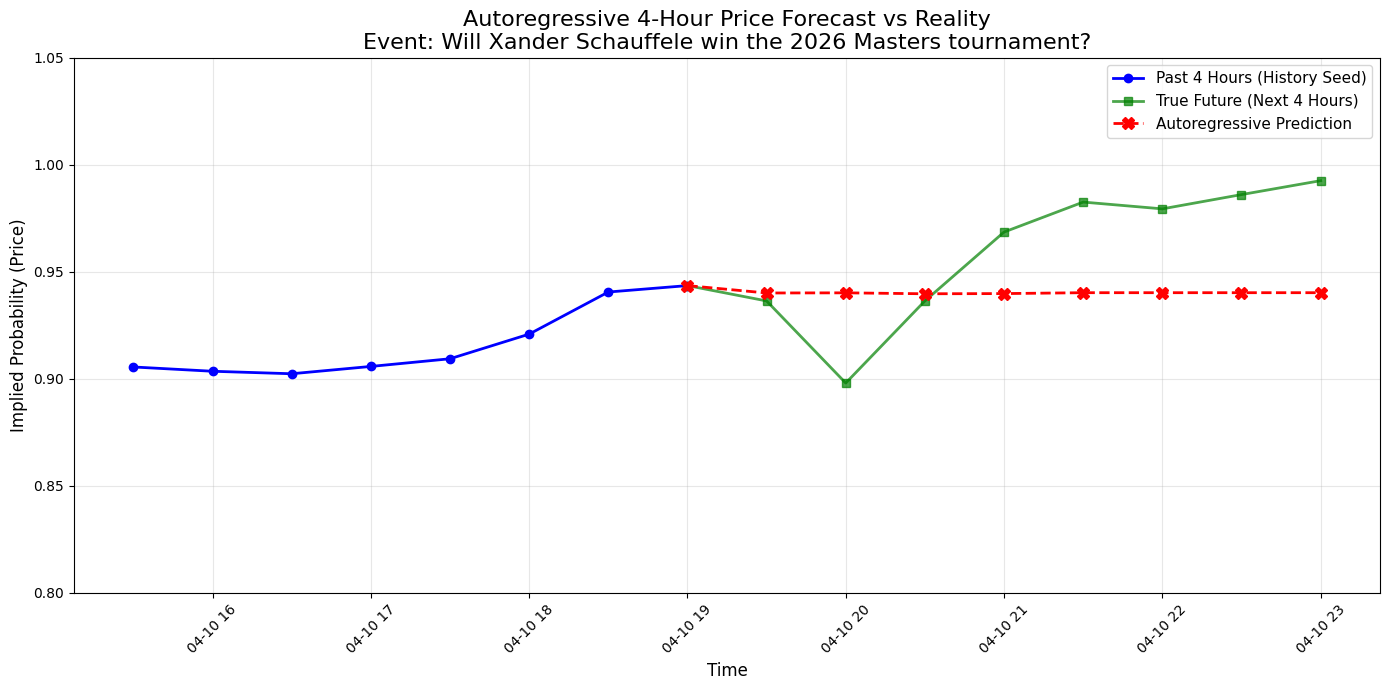


Top 2 Event (Highest Variance): Will the Charlotte Hornets win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0048
MAE (Mean Absolute Error):      0.0040
Directional Accuracy:           62.5%



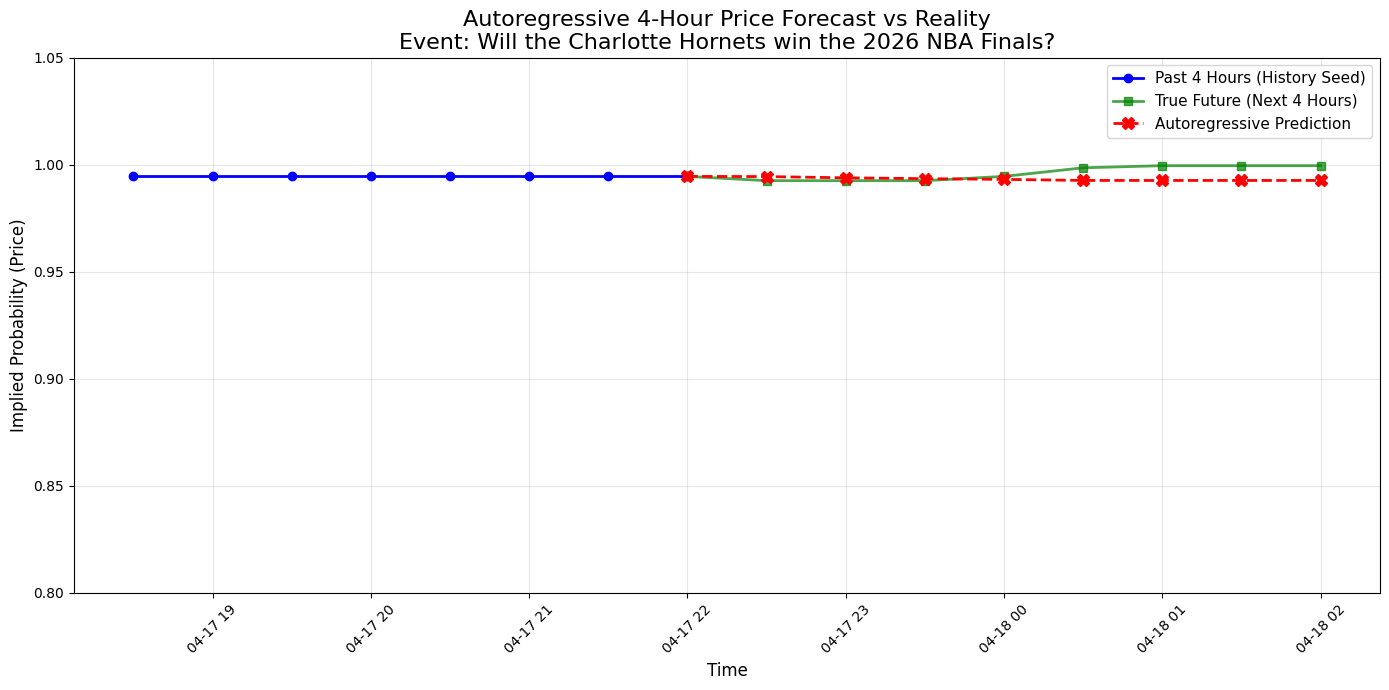


Top 3 Event (Highest Variance): Will the Golden State Warriors win the NBA Western Conference Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0049
MAE (Mean Absolute Error):      0.0038
Directional Accuracy:           62.5%



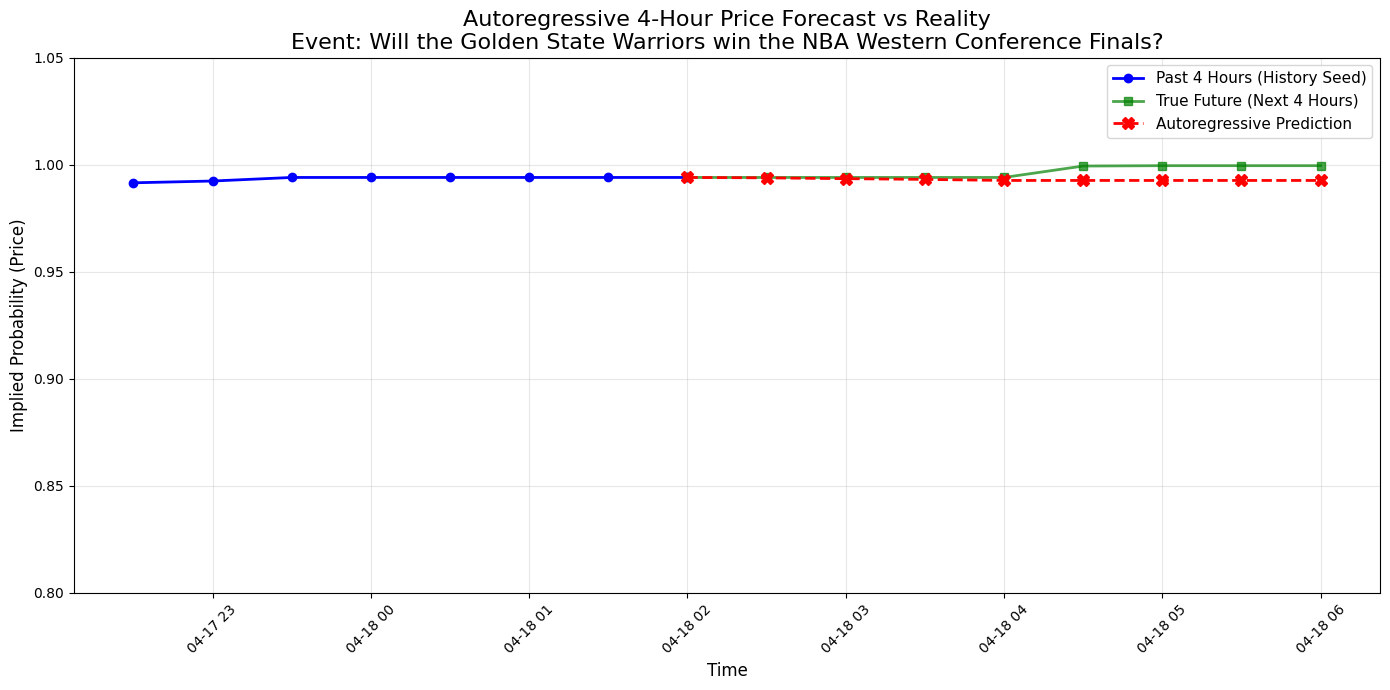


Top 4 Event (Highest Variance): Will the Golden State Warriors win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0043
MAE (Mean Absolute Error):      0.0038
Directional Accuracy:           25.0%



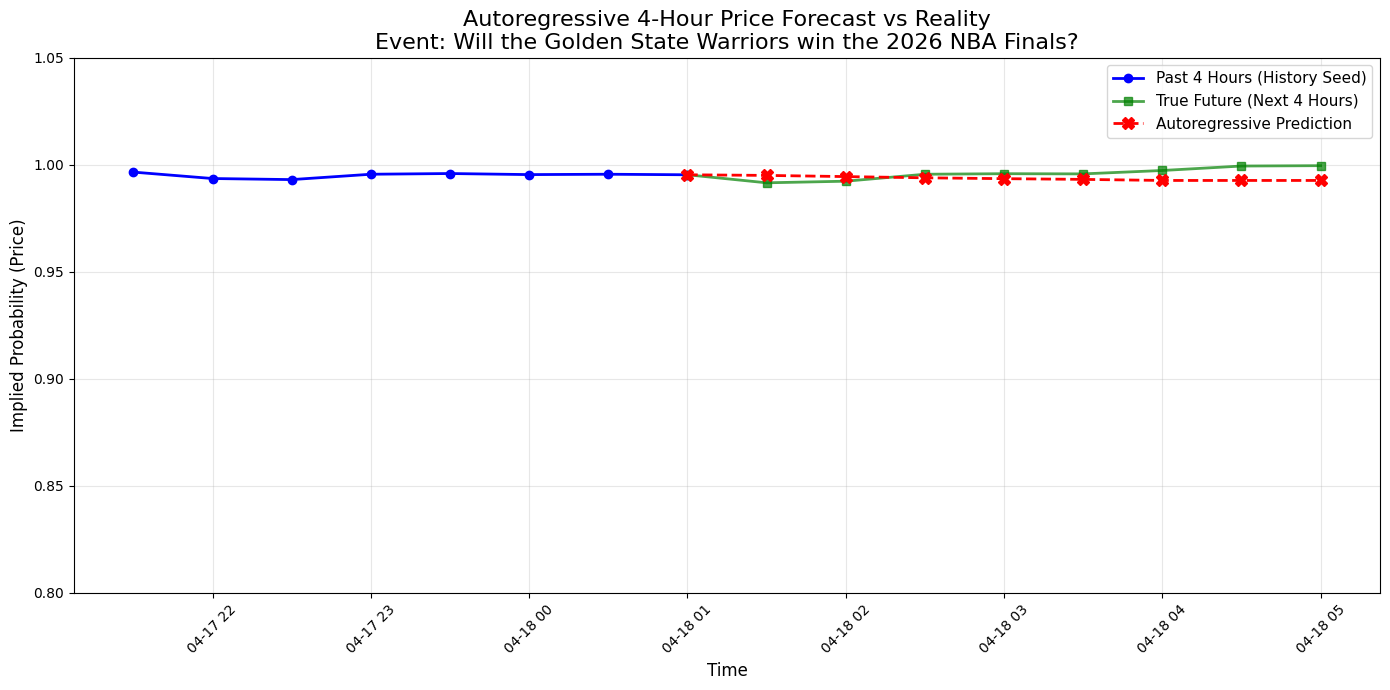


Top 5 Event (Highest Variance): Will the Iranian regime fall by March 31?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0027
MAE (Mean Absolute Error):      0.0021
Directional Accuracy:           50.0%



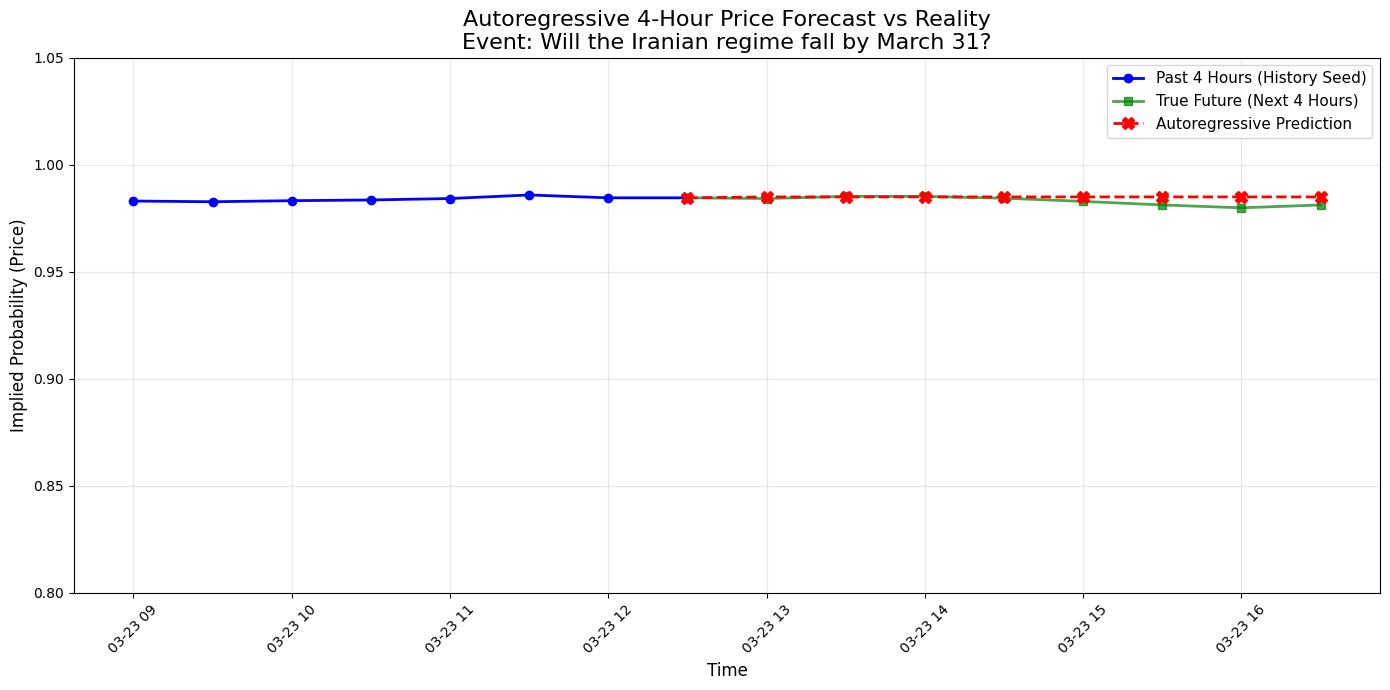


Top 6 Event (Highest Variance): Will the Los Angeles Clippers win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0025
MAE (Mean Absolute Error):      0.0021
Directional Accuracy:           37.5%



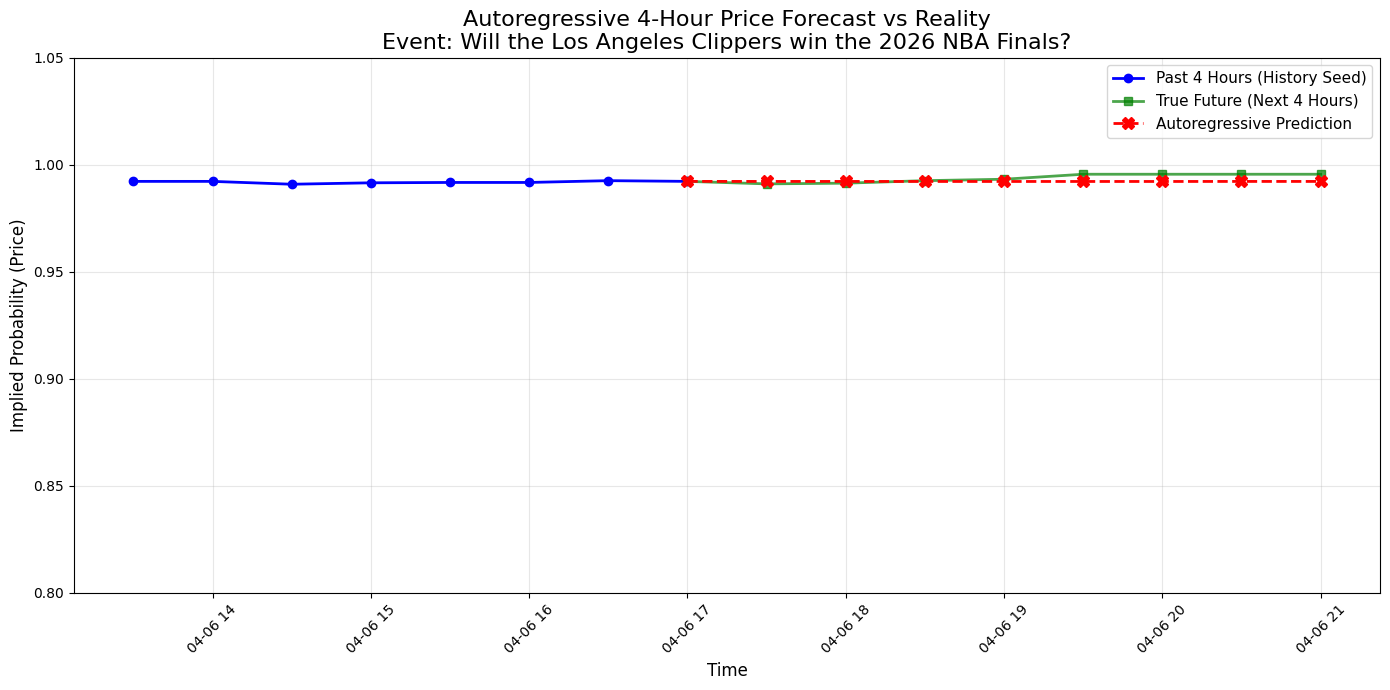


Top 7 Event (Highest Variance): Will the Miami Heat win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0023
MAE (Mean Absolute Error):      0.0019
Directional Accuracy:           75.0%



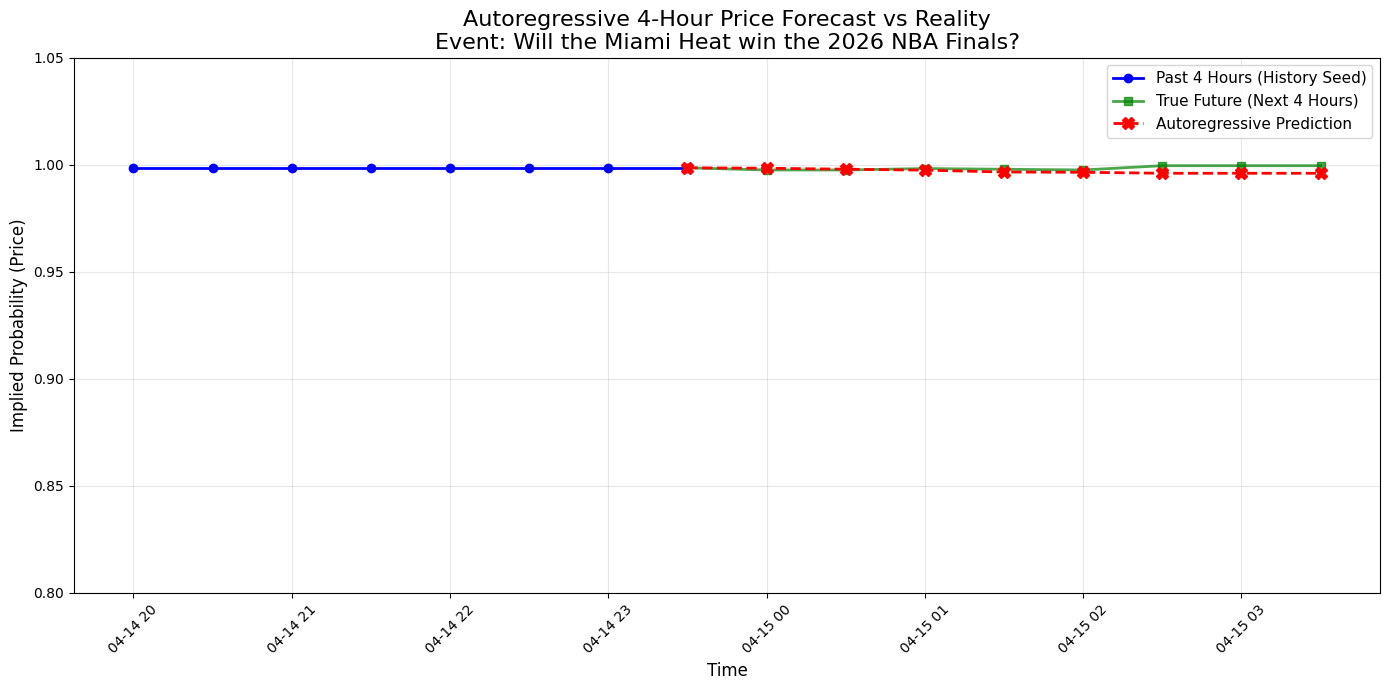


Top 8 Event (Highest Variance): Will the Chicago Bulls win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0026
MAE (Mean Absolute Error):      0.0022
Directional Accuracy:           75.0%



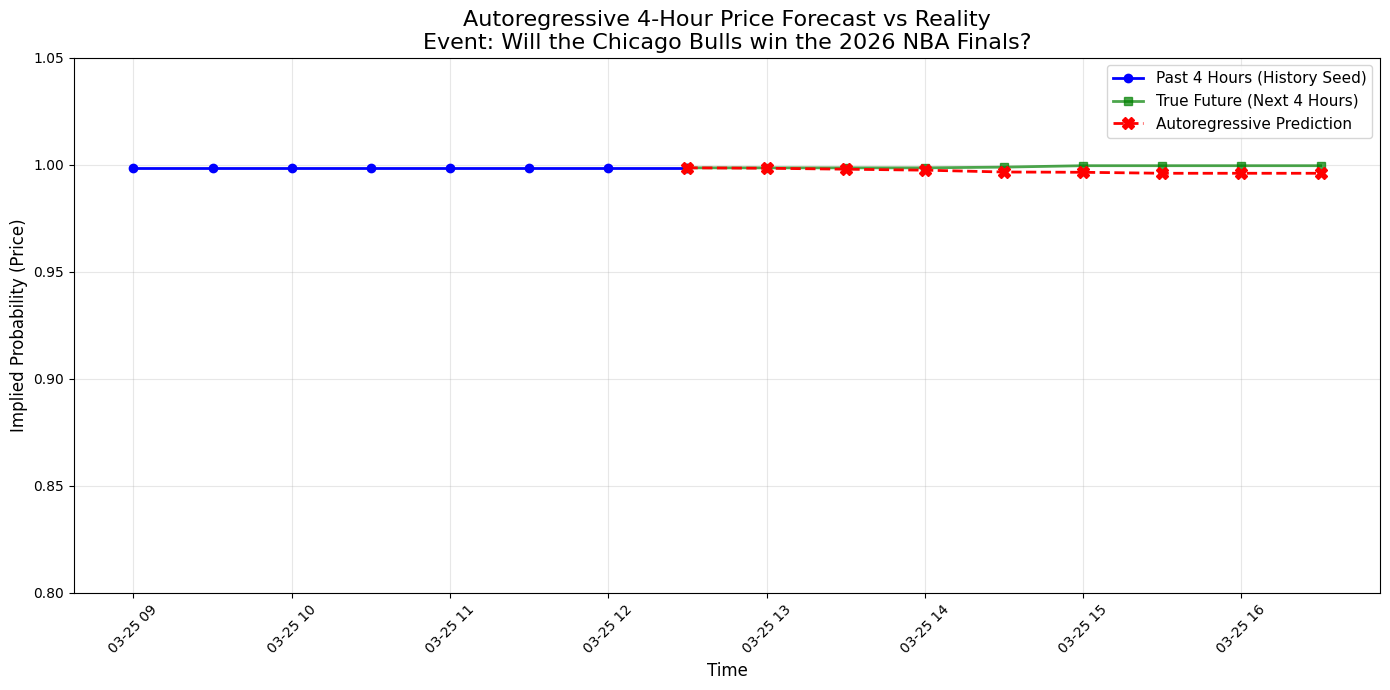


Top 9 Event (Highest Variance): Will the Democratic Coalition (DK) win the most seats in the next Hungarian parliamentary election?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0022
MAE (Mean Absolute Error):      0.0018
Directional Accuracy:           62.5%



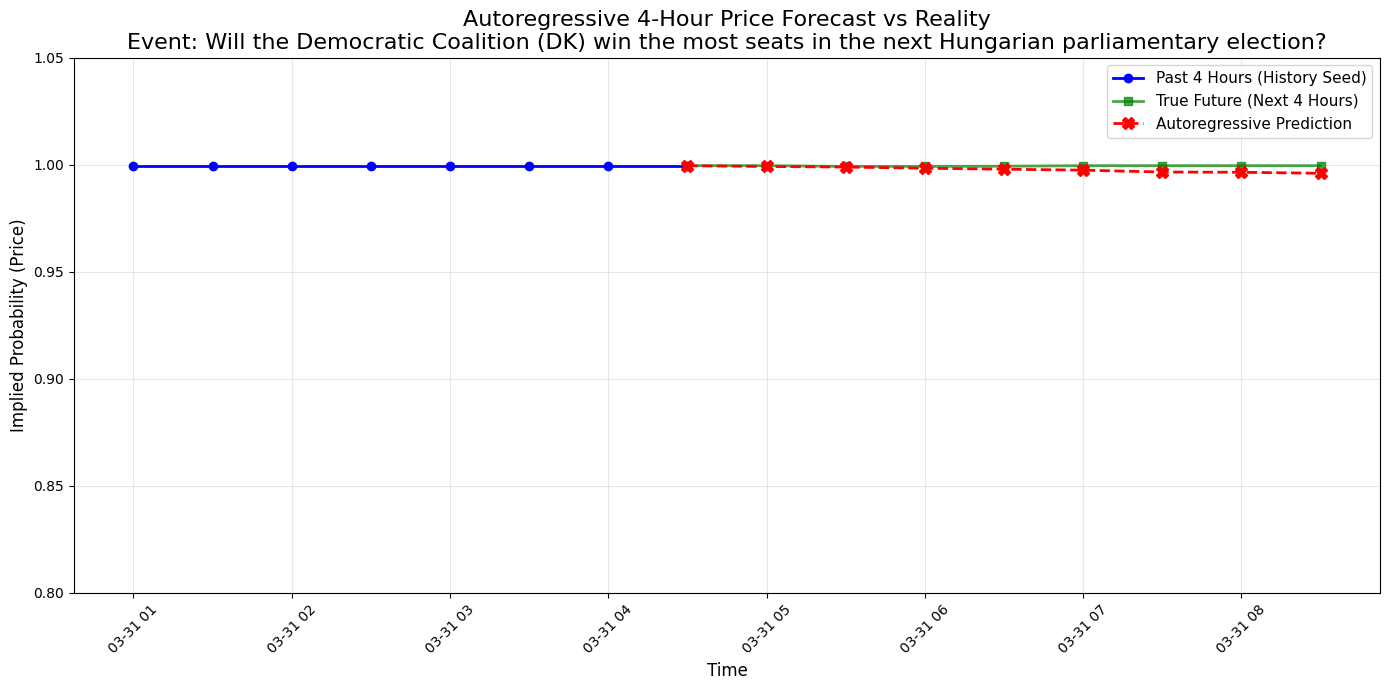

In [ ]:
# 1. Select a valid event from the test set that has at least 8 remaining steps
test_df = df_ml.iloc[split_idx:].copy()
valid_events = test_df['Event_name'].value_counts()
valid_events = valid_events[valid_events >= 8].index

# Find sequences with the highest min-max deviation in their 8-step forward window for each event
event_max_deviations = []

for event in valid_events:
    event_data = test_df[test_df['Event_name'] == event].reset_index()
    max_deviation = -1
    best_start_idx = 0
    for i in range(len(event_data) - 7):  # Ensure there are 8 remaining steps
        future_window = event_data.iloc[i : i + 8]['price']
        deviation = future_window.max() - future_window.min()
        if deviation > max_deviation:
            max_deviation = deviation
            best_start_idx = i
    if max_deviation >= 0:
        event_max_deviations.append((max_deviation, event, best_start_idx))

# Sort descending and get top 5
event_max_deviations.sort(reverse=True, key=lambda x: x[0])
top_events = event_max_deviations[:5]

for rank, (dev, sample_event, best_start_idx) in enumerate(top_events, 1):
    print(f"\n{'='*50}")
    print(f"Top {rank} Event (Highest Min-Max Deviation: {dev:.4f}): {sample_event}")
    print(f"{'='*50}\n")
    
    event_test_data = test_df[test_df['Event_name'] == sample_event].reset_index()

    # 2. Extract the initial state (the seed)
    start_row = event_test_data.iloc[best_start_idx]
    start_datetime = start_row['datetime']

    current_sequence = [start_row[f'price_lag_{i}'] for i in range(window_size, 0, -1)]
    feature_row = start_row[feature_cols].copy()
    predictions = []

    # 3. Recursive Forecasting (8 steps = 4 hours)
    for step in range(8):
        pred_df_row = pd.DataFrame([feature_row], columns=feature_cols).astype(X_train.dtypes.to_dict())
        
        pred_price = float(model.predict(pred_df_row)[0])
        pred_price = float(np.clip(pred_price, 0, 1))
        predictions.append(pred_price)
        
        current_sequence.append(pred_price)
        
        for i in range(1, window_size + 1):
            feature_row[f'price_lag_{i}'] = current_sequence[-i]
            
        feature_row['rolling_mean_4h'] = np.mean(current_sequence[-window_size:])
        feature_row['rolling_std_4h'] = np.std(current_sequence[-window_size:], ddof=1)

    # 4. Gather True Data for comparision
    df_30m_event = df_30m[df_30m['Event_name'] == sample_event].reset_index(drop=True)
    start_idx_30m = df_30m_event[df_30m_event['datetime'] == start_datetime].index[0]

    history_df = df_30m_event.iloc[start_idx_30m - window_size : start_idx_30m].copy()
    future_df = df_30m_event.iloc[start_idx_30m : start_idx_30m + 8].copy()

    pred_df = future_df.copy()
    pred_df['price'] = predictions

    last_history_time = history_df['datetime'].iloc[-1]
    last_history_price = history_df['price'].iloc[-1]

    # 5. Evaluate Forecasting Metrics
    true_future_prices = future_df['price'].values
    pred_future_prices = np.array(predictions)

    ar_rmse = np.sqrt(mean_squared_error(true_future_prices, pred_future_prices))
    ar_mae = mean_absolute_error(true_future_prices, pred_future_prices)

    true_direction = np.diff([last_history_price] + list(true_future_prices)) > 0
    pred_direction = np.diff([last_history_price] + list(pred_future_prices)) > 0
    directional_accuracy = np.mean(true_direction == pred_direction) * 100

    print("=== 4-Hour Forecast Metrics ===")
    print(f"RMSE (Root Mean Squared Error): {ar_rmse:.4f}")
    print(f"MAE (Mean Absolute Error):      {ar_mae:.4f}")
    print(f"Directional Accuracy:           {directional_accuracy:.1f}%\n")

    # 6. Plotting
    plt.figure(figsize=(14, 7))

    plt.plot(history_df['datetime'], history_df['price'], label='Past 4 Hours (History Seed)', color='blue', marker='o', linewidth=2)

    true_times = [last_history_time] + future_df['datetime'].tolist()
    true_prices = [last_history_price] + future_df['price'].tolist()
    pred_prices = [last_history_price] + pred_df['price'].tolist()

    plt.plot(true_times, true_prices, label='True Future (Next 4 Hours)', color='green', linestyle='-', marker='s', linewidth=2, alpha=0.7)
    plt.plot(true_times, pred_prices, label='Autoregressive Prediction', color='red', linestyle='--', marker='X', markersize=8, linewidth=2)

    plt.title(f'Autoregressive 4-Hour Price Forecast vs Reality\nEvent: {sample_event}', fontsize=16)
    plt.xlabel('Time', fontsize=12)
    plt.ylabel('Implied Probability (Price)', fontsize=12)
    plt.ylim(-0.05, 1.05) # Reverted to normal full percentage boundaries to see full variation
    plt.grid(alpha=0.3)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()